In [397]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,roc_curve, auc,mean_squared_error,recall_score,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV,HalvingGridSearchCV
from tqdm import tqdm
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
import xgboost as xgb
import os
import shap

In [398]:
import shap, xgboost
print(shap.__version__, xgboost.__version__)

0.49.1 3.0.5


In [399]:
feature_PATH = "../data/processed/features/feature_cols.csv"
feature_cols = pd.read_csv(feature_PATH)["feature"].tolist()

response_PATH = "../data/processed/response_cols/response_cols.csv"
response_cols = pd.read_csv(response_PATH)["response"].tolist()

train_data = pd.DataFrame() 
train_PATH = f"../data/processed/train/train_data.parquet"
train_data = pd.concat([train_data, pd.read_parquet(train_PATH)])

test_data = pd.DataFrame() 
test_PATH = f"../data/processed/test/test_data.parquet"
test_data = pd.concat([test_data , pd.read_parquet(test_PATH)])

In [400]:
common = train_data.columns.intersection(test_data.columns)
object_cols = train_data[common].select_dtypes(include=["object"]).columns

for col in object_cols:
    cats = pd.concat([train_data[col], test_data[col]]).dropna().unique()
    dtype = pd.CategoricalDtype(categories=cats)
    train_data[col] = train_data[col].astype(dtype)
    test_data[col] = test_data[col].astype(dtype)

In [401]:
attr = "wrong_call"

In [402]:
train_features, test_features = train_data[feature_cols].drop(columns=["pitcher","batter"]) , test_data[feature_cols].drop(columns=["pitcher","batter"])
train_response, test_response = train_data[response_cols][attr] , test_data[response_cols][attr]

In [403]:
umps = list(pd.concat([train_features, test_features])["hp_official_id"].unique())


In [404]:
cv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    random_state=6740,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    enable_categorical=True,
    n_jobs=1,
    device = "cuda",
    scale_pos_weight=100 
)

pipe = Pipeline(steps=[("xgb", xgb_model)])

param_grid = {
"xgb__learning_rate":    [ 0.065 , 0.075],
"xgb__max_depth":        [7, 10],
"xgb__min_child_weight": [65, 70,],
"xgb__reg_lambda":       [20, 25],
}

search = HalvingGridSearchCV(
    pipe, param_grid,
    cv=cv,
    scoring="average_precision",
    n_jobs=4,
    verbose=2,
    error_score="raise",
    factor=3,
    resource="xgb__n_estimators",
    max_resources=550,
    min_resources="exhaust"
)


search.fit(train_features, train_response)

print("Best params:", search.best_params_)
print("Best CV PR-AUC:", search.best_score_)
print("Final n_estimators:", search.best_estimator_.named_steps["xgb"].n_estimators)

n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 61
max_resources_: 550
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 16
n_resources: 61
Fitting 5 folds for each of 16 candidates, totalling 80 fits
----------
iter: 1
n_candidates: 6
n_resources: 183
Fitting 5 folds for each of 6 candidates, totalling 30 fits
----------
iter: 2
n_candidates: 2
n_resources: 549
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best params: {'xgb__learning_rate': 0.065, 'xgb__max_depth': 7, 'xgb__min_child_weight': 70, 'xgb__reg_lambda': 25, 'xgb__n_estimators': 549}
Best CV PR-AUC: 0.29349328027485083
Final n_estimators: 549


In [405]:
final_model = clone(pipe).set_params(**search.best_params_)
final_model.fit(train_features, train_response)

xgb_train_probs = final_model.predict_proba(train_features)[:, 1]
xgb_test_probs  = final_model.predict_proba(test_features)[:, 1]

pr, rc, th = precision_recall_curve(train_response, xgb_train_probs)
thr = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]
# thr = .99
xgb_train_preds = (xgb_train_probs >= thr).astype(int)
xgb_test_preds  = (xgb_test_probs  >= thr).astype(int)

for name, yt, pp, pl in [("Train", train_response, xgb_train_probs, xgb_train_preds),
                         ("Test",  test_response,  xgb_test_probs,  xgb_test_preds)]:
    print(f"XGB {name}: LogLoss {log_loss(yt, pp):.4f} | ROC-AUC {roc_auc_score(yt, pp):.4f} | "
          f"PR-AUC {average_precision_score(yt, pp):.4f} | F1 {f1_score(yt, pl):.4f} | base rate {yt.mean():.3f}")

results = pd.DataFrame({
    'actual':     pd.concat([train_response, test_response]).values,
    'pred_prob':  np.concatenate([xgb_train_probs, xgb_test_probs]),
    'pred_label': np.concatenate([xgb_train_preds, xgb_test_preds]),
    'split':      ['train'] * len(train_response) + ['test'] * len(test_response)})

XGB Train: LogLoss 1.2520 | ROC-AUC 0.8614 | PR-AUC 0.3526 | F1 0.3962 | base rate 0.093
XGB Test: LogLoss 1.3230 | ROC-AUC 0.8138 | PR-AUC 0.2496 | F1 0.3070 | base rate 0.081


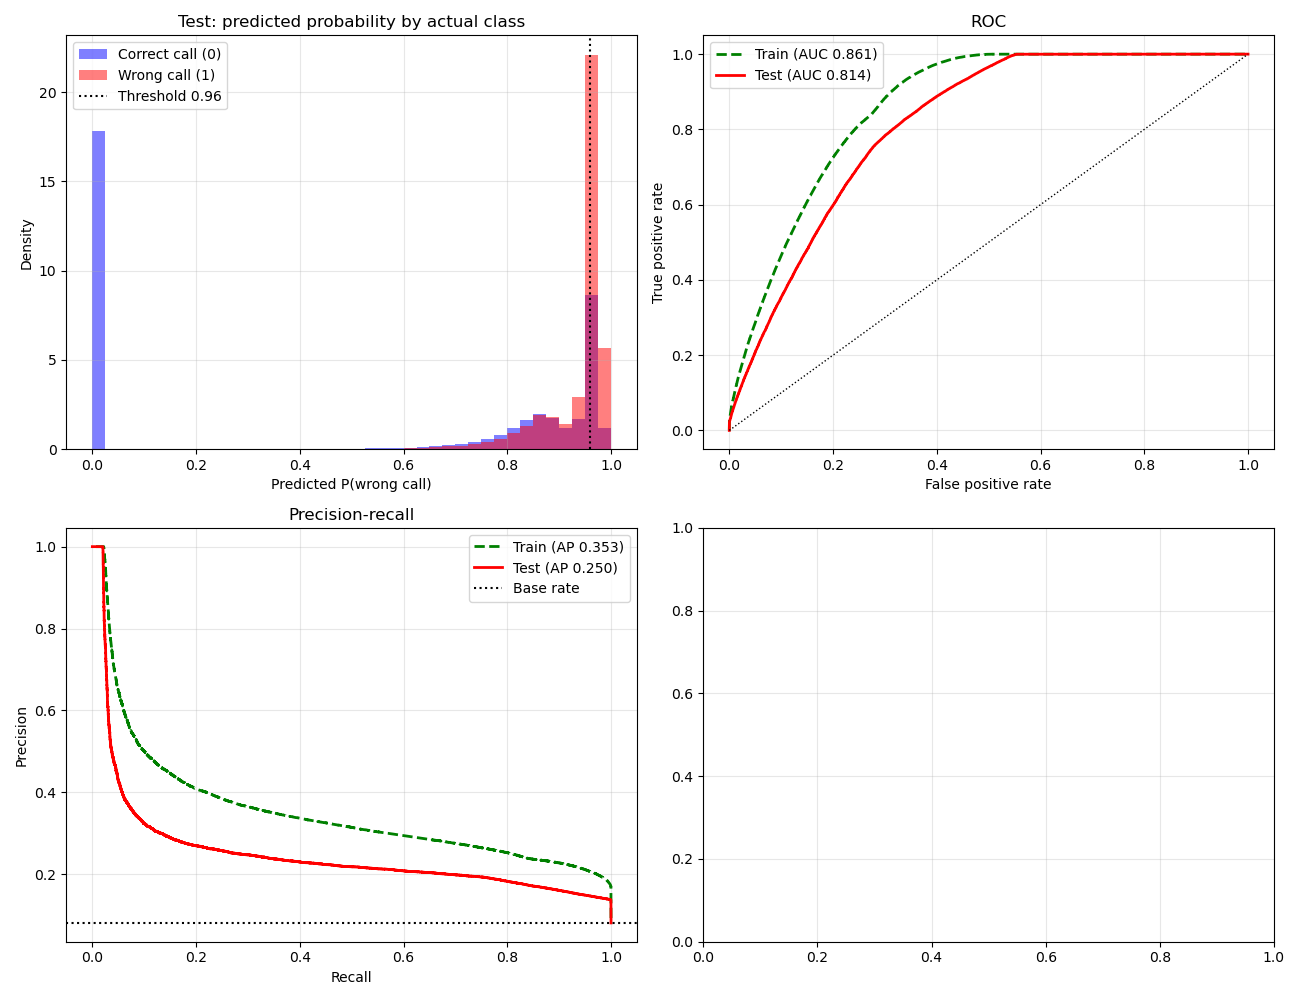

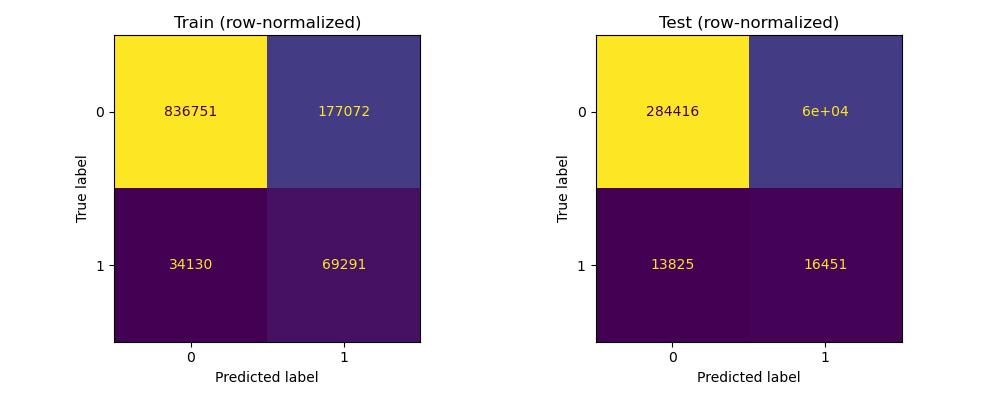

In [406]:
%matplotlib widget
plt.close("all")
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Wrong call (1)')]:
    ax[0, 0].hist(xgb_test_probs[test_response.values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(wrong call)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC'); ax[0, 1].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(test_response.mean(), color='black', linestyle=':', linewidth=1.5, label='Base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall'); ax[1, 0].legend()

# fp, mp = calibration_curve(test_response, xgb_test_probs, n_bins=10, strategy='quantile')
# ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='XGB (test)')
# ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
# ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction wrong', title='Calibration (test)')
# ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Diagnostics.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pl, ttl in [(ax[0], train_response, xgb_train_preds, 'Train'), (ax[1], test_response, xgb_test_preds, 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pl, ax=a, colorbar=False, 
    # normalize='true', 
    # values_format='.2f'
    )
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Confusion.png", dpi=300)
plt.show()

In [407]:
# train_features["attack_zone"].unique()

In [408]:
from sklearn.metrics import recall_score, precision_score, average_precision_score

for name, X, y in [("train", train_features, train_response), ("test", test_features, test_response)]:
    p = search.best_estimator_.predict_proba(X)[:, 1]
    print(name, "PR-AUC:", round(average_precision_score(y, p), 4))
    for t in [0.25, 0.5, 0.75,.99]:
        pred = p >= t
        print(f"  t={t}: recall={recall_score(y, pred):.3f} precision={precision_score(y, pred):.3f}")

train PR-AUC: 0.3526
  t=0.25: recall=1.000 precision=0.162
  t=0.5: recall=1.000 precision=0.163
  t=0.75: recall=0.999 precision=0.172
  t=0.99: recall=0.022 precision=0.995
test PR-AUC: 0.2496
  t=0.25: recall=1.000 precision=0.137
  t=0.5: recall=0.998 precision=0.137
  t=0.75: recall=0.975 precision=0.143
  t=0.99: recall=0.021 precision=0.987


In [409]:
OUT_DIR = "../results/raw"
os.makedirs(OUT_DIR, exist_ok=True)

# `results` was already built after the model fit cell; reuse it.
preds_df = results.copy()

preds_path = os.path.join(OUT_DIR, "xgb_predictions_vs_actuals.csv")
preds_df.to_csv(preds_path, index=False)
print(f"Saved {len(preds_df):,} rows -> {preds_path}")
print(preds_df.head())

Saved 1,492,386 rows -> ../results/raw\xgb_predictions_vs_actuals.csv
   actual  pred_prob  pred_label  split
0       0   0.967474           1  train
1       1   0.925060           0  train
2       0   0.001711           0  train
3       0   0.834592           0  train
4       0   0.000216           0  train


In [410]:
OUT_DIR = "../results/stats"
os.makedirs(OUT_DIR, exist_ok=True)
def _metric_row(y_true, prob, pred, threshold):
    return {
        "threshold":  threshold,
        "log_loss":   log_loss(y_true, prob),
        "roc_auc":    roc_auc_score(y_true, prob),
        "pr_auc":     average_precision_score(y_true, prob),
        "accuracy":   accuracy_score(y_true, pred),
        "precision":  precision_score(y_true, pred, zero_division=0),
        "recall":     recall_score(y_true, pred, zero_division=0),
        "f1":         f1_score(y_true, pred, zero_division=0),
        "base_rate":  float(np.mean(y_true)),
        "n_rows":     len(y_true),
    }

metrics_df = pd.DataFrame([
    {"split": "train", **_metric_row(train_response, xgb_train_probs, xgb_train_preds, thr)},
    {"split": "test",  **_metric_row(test_response,  xgb_test_probs,  xgb_test_preds,  thr)},
])

metrics_path = os.path.join(OUT_DIR, "xgb_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved metrics -> {metrics_path}")
display(metrics_df)

Saved metrics -> ../results/stats\xgb_metrics.csv


,split,threshold,log_loss,roc_auc,pr_auc,accuracy,precision,recall,f1,base_rate,n_rows
0,train,0.960209,1.252021,0.861419,0.352616,0.810962,0.281256,0.669990,0.396193,0.092568,1117244
1,test,0.960209,1.323008,0.813820,0.249581,0.802008,0.213924,0.543368,0.306988,0.080705,375142


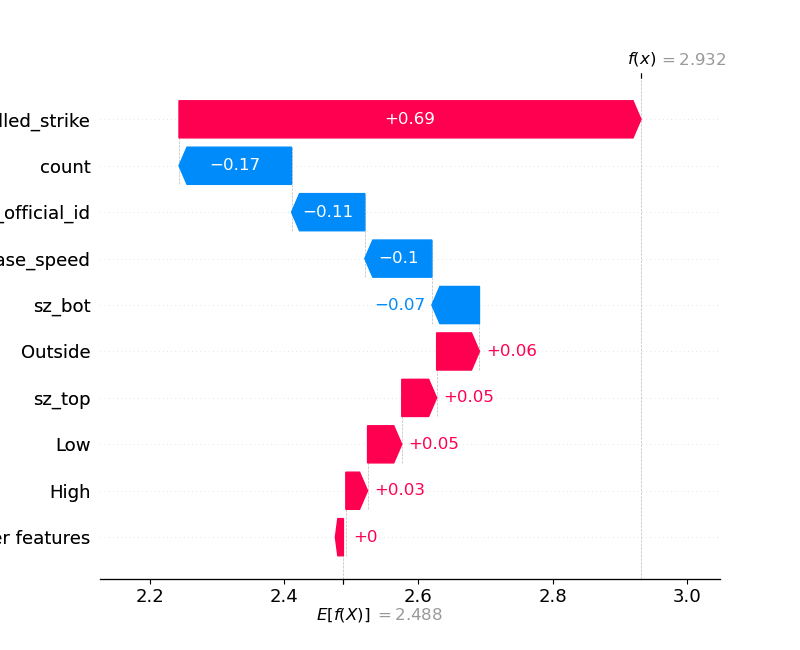

In [411]:
plt.close("all")
xgb_fitted = final_model.named_steps["xgb"]
booster = xgb_fitted.get_booster()

dtest = xgb.DMatrix(test_features, enable_categorical=True)

shap_raw = booster.predict(dtest, pred_contribs=True)

shap_values = shap_raw[:, :-1]
base_values = shap_raw[:, -1]

# shap.summary_plot(
#     shap_values,
#     features=None,
#     feature_names=test_features.columns.tolist(),
#     plot_type="bar",
#     max_display=10
# )

shap_exp = shap.Explanation(
    values=shap_values[25],
    base_values=base_values[25],
    feature_names=test_features.columns.tolist()
)

shap.plots.waterfall(shap_exp)


In [412]:
# xgb_model.save_model("stl_xgboost.json")
# X_combined.to_csv("stl_xgboost_xvals.csv")